In [16]:
from alphagenome import colab_utils
from alphagenome.data import gene_annotation, genome, track_data, transcript
from alphagenome.models import dna_client
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [17]:
API_KEY = "***REMOVED***"

dna_model = dna_client.create(API_KEY)

In [18]:
output_metadata = dna_model.output_metadata(
    organism=dna_client.Organism.HOMO_SAPIENS
)

In [19]:
# Load gene annotations (from GENCODE).
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)

# Filter to protein-coding genes and highly supported transcripts.
gtf_transcript = gene_annotation.filter_transcript_support_level(
    gene_annotation.filter_protein_coding(gtf), ['1']
)

# Extractor for identifying transcripts in a region.
transcript_extractor = transcript.TranscriptExtractor(gtf_transcript)

# Also define an extractor that fetches only the longest transcript per gene.
gtf_longest_transcript = gene_annotation.filter_to_longest_transcript(
    gtf_transcript
)
longest_transcript_extractor = transcript.TranscriptExtractor(
    gtf_longest_transcript
)

In [20]:
# Define interval to make predictions for (used throughout this tutorial).
# Note that the interval width must be one of the supported sequence lengths.
interval = genome.Interval('chr10', 89624223, 89625057).resize(
    dna_client.SEQUENCE_LENGTH_1MB
)

# Define the tissues/cell-types to predict expression for.
ontology_terms = [
    'UBERON:0001159',  # Colon - Sigmoid.
    'UBERON:0001155',  # Colon - Transverse.
]

# Make predictions.
output = dna_model.predict_interval(
    interval=interval,
    requested_outputs={
        dna_client.OutputType.RNA_SEQ,
        dna_client.OutputType.CAGE,
    },
    ontology_terms=ontology_terms,
)

# Extract the longest transcripts per gene for this interval.
longest_transcripts = longest_transcript_extractor.extract(interval)

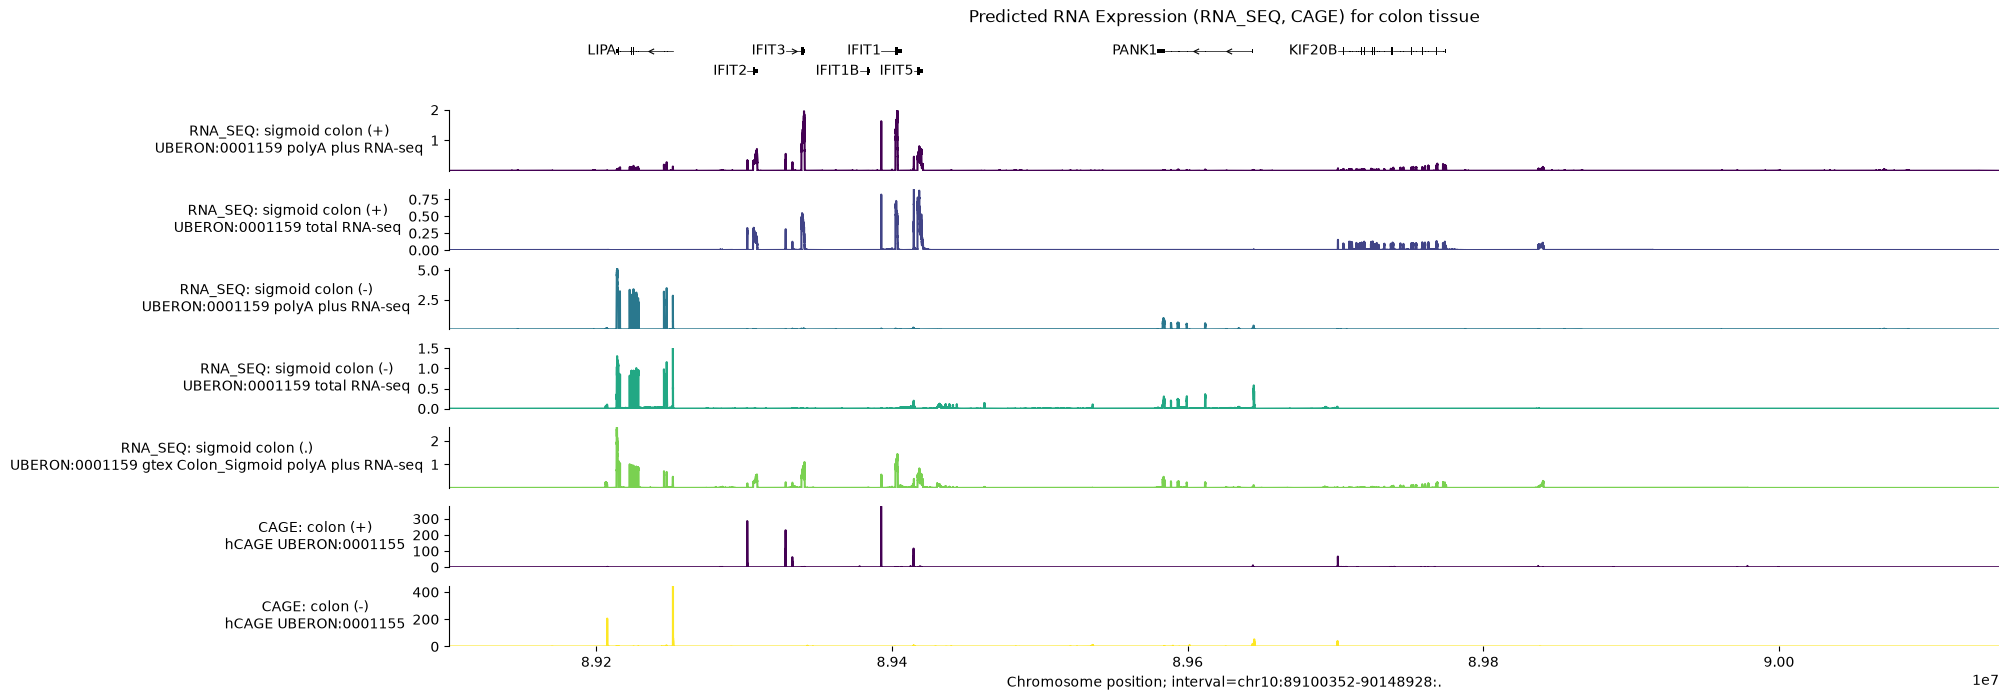

In [21]:
# Build plot.
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=output.rna_seq,
            ylabel_template='RNA_SEQ: {biosample_name} ({strand})\n{name}',
        ),
        plot_components.Tracks(
            tdata=output.cage,
            ylabel_template='CAGE: {biosample_name} ({strand})\n{name}',
        ),
    ],
    interval=interval,
    title='Predicted RNA Expression (RNA_SEQ, CAGE) for colon tissue',
)

In [22]:
# Run once on any interval, then inspect which biosamples/ontology CURIEs exist
output = dna_model.predict_interval(
    interval=interval,
    requested_outputs=[dna_client.OutputType.RNA_SEQ],
)

meta = output.rna_seq.metadata  # DataFrame with biosample_name, ontology_curie, tissue, assay
breast_tracks = meta[meta.biosample_name.str.contains('breast|mammary', case=False)]
print(breast_tracks[['biosample_name', 'ontology_curie', 'assay_title']])

TypeError: DnaClient.predict_interval() missing 1 required keyword-only argument: 'ontology_terms'

In [ ]:
output = dna_model.predict_variant(
    interval=variant.reference_interval.resize(2**20),  # 1 Mb input
    variant=genome.Variant(chromosome='chr10', position=89624223,
                           reference_bases='A', alternate_bases='G'),
    requested_outputs=[dna_client.OutputType.RNA_SEQ],
    ontology_terms=['UBERON:0001911'],
)

NameError: name 'variant' is not defined